# 05 — Stratified Folds, Leakage, Acquisition Shortcuts & Cleaning Checklist

This final notebook audits the **benchmark evaluation protocol (`strat_fold` 1–10)** and searches for **confounders / batch effects** that can silently inflate or distort ML evaluation:

1. **Zero Patient Leakage Verification**: Confirming `patient_id` disjointness across all 10 stratified folds.
2. **The Fold 9–10 Human-Validation Skew**: Quantifying how PTB-XL concentrates gold-standard `validated_by_human == True` ECGs into validation (`fold 9`) and test (`fold 10`), leaving noisy unvalidated machine labels concentrated in `train` (`folds 1–8`).
3. **Acquisition Confounders (`device`, `site`) & Clinical Cross-Checks**: Measuring shortcut-learning risk (`device` × `diagnostic_class` association) and auditing internal consistency between `infarction_stadium1` and `MI` SCP codes.
4. **Multivariate Signal Feature Space (PCA + Outlier Detection)**: Checking whether recorder hardware (`device`) clusters separately in signal-statistics space.
5. **Consolidated PTB-XL Data Cleaning Checklist**: Concrete recommendations for `ptbxl/dataset.py`.

In [1]:
import ast
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from scipy import signal as sp_signal

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "data" / "ptbxl_database.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/data/ptbxl_database.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "ptbxl" / "data"
print(f"Repo root : {REPO_ROOT}")
print(f"Data dir  : {DATA_DIR}")

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from ptbxl import PTBXLDataset

LEADS = PTBXLDataset.LEADS
df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df["scp_dict"] = df["scp_codes"].apply(ast.literal_eval)
df["device_clean"] = df["device"].astype(str).str.strip()
scp_df = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
diag_scp = scp_df[scp_df["diagnostic"] == 1.0]

ds_helper = PTBXLDataset.__new__(PTBXLDataset)
df["superclass"] = df["scp_dict"].apply(lambda d: ds_helper._aggregate_class(d, diag_scp))

# 1. Exact patient_id leakage check across all 10 folds
fold_patients = {f: set(df.loc[df["strat_fold"] == f, "patient_id"].dropna()) for f in range(1, 11)}
overlaps = [
    (f1, f2, len(fold_patients[f1] & fold_patients[f2]))
    for f1 in range(1, 11) for f2 in range(f1 + 1, 11)
    if len(fold_patients[f1] & fold_patients[f2]) > 0
]
print(f"Pairwise patient_id overlaps across folds 1..10: {len(overlaps)} (0 = strictly leak-free!)")

Repo root : /nfs/data8/schlegel/git/ecg-data-repo
Data dir  : /nfs/data8/schlegel/git/ecg-data-repo/ptbxl/data


Pairwise patient_id overlaps across folds 1..10: 0 (0 = strictly leak-free!)


## 5.1 Stratified Fold Balance & The Fold 9–10 Label-Quality Skew

While PTB-XL's `strat_fold` balances diagnostic labels, age, and sex across all 10 folds, **folds 9 and 10 were deliberately constructed as high-quality evaluation folds** (`validated_by_human` near 100%). Let's quantify this asymmetry across folds `1–10`!

,n_ecgs,n_patients,pct_human_validated,pct_autogen_unval,pct_noise_flagged,mean_age_valid,pct_female
strat_fold,,,,,,,
1,2175,1878,67.26,32.74,18.48,59.34,47.77
2,2181,1849,66.30,33.70,16.78,59.08,47.91
3,2192,1887,66.97,33.03,18.52,59.21,48.18
4,2174,1883,68.12,31.88,16.19,59.71,47.70
5,2174,1890,67.71,32.29,17.62,59.36,47.65
6,2173,1884,64.15,35.85,17.35,59.33,47.72
7,2176,1871,67.92,32.08,17.88,59.47,47.75
8,2173,1881,67.79,32.21,17.58,59.31,47.86
9,2183,1942,100.00,0.00,17.18,59.88,48.10


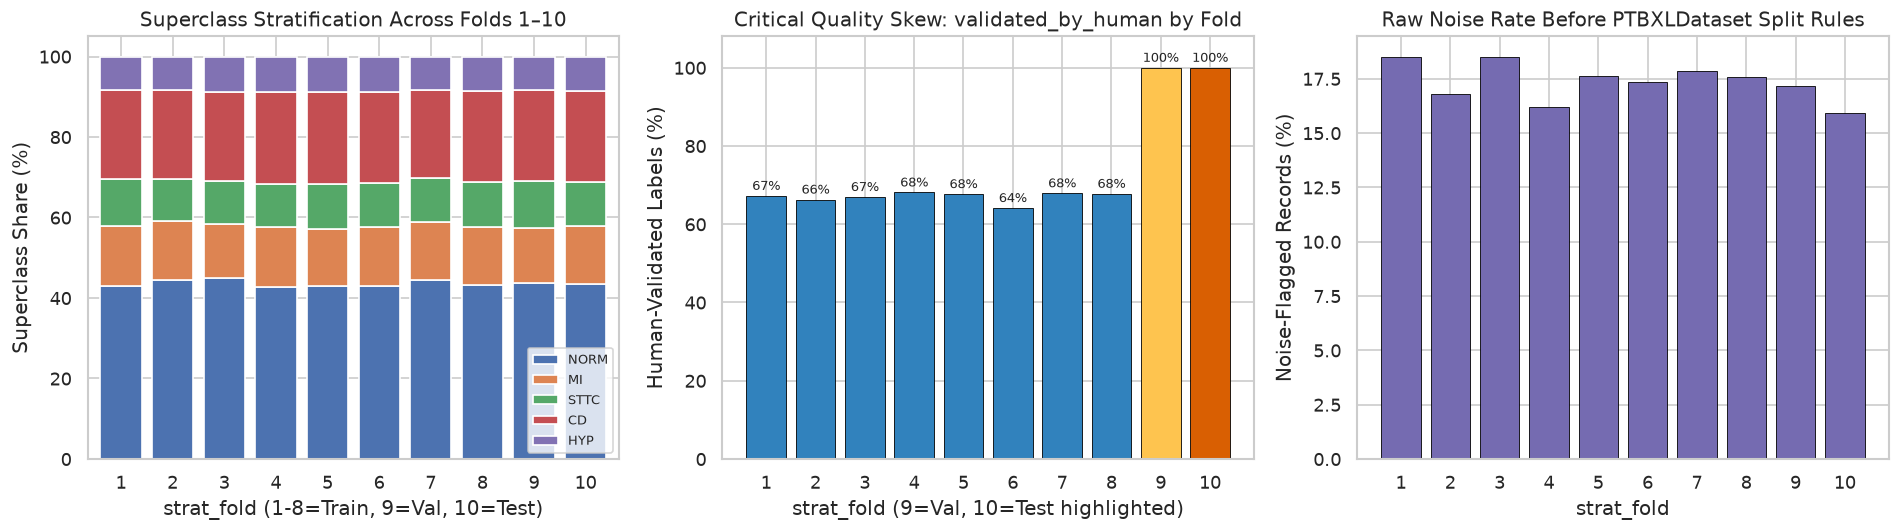

In [2]:
fold_stats = pd.DataFrame({
    "n_ecgs": df.groupby("strat_fold").size(),
    "n_patients": df.groupby("strat_fold")["patient_id"].nunique(),
    "pct_human_validated": df.groupby("strat_fold")["validated_by_human"].mean() * 100,
    "pct_autogen_unval": (~df["validated_by_human"]).groupby(df["strat_fold"]).mean() * 100,
    "pct_noise_flagged": df[["static_noise", "burst_noise", "electrodes_problems"]].notna().any(axis=1).groupby(df["strat_fold"]).mean() * 100,
    "mean_age_valid": df[df["age"] <= 100].groupby("strat_fold")["age"].mean(),
    "pct_female": df.groupby("strat_fold")["sex"].mean() * 100,
})
display(fold_stats.round(2))

fold_super = pd.crosstab(df["strat_fold"], df["superclass"], normalize="index") * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

fold_super[["NORM", "MI", "STTC", "CD", "HYP"]].plot(kind="bar", stacked=True, ax=axes[0], width=0.8)
axes[0].set_xlabel("strat_fold (1-8=Train, 9=Val, 10=Test)")
axes[0].set_ylabel("Superclass Share (%)")
axes[0].set_title("Superclass Stratification Across Folds 1–10")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=7.5, loc="lower right")

bar_colors = ["#3182bd"] * 8 + ["#fec44f", "#d95f02"]
axes[1].bar(fold_stats.index.astype(str), fold_stats["pct_human_validated"], color=bar_colors, edgecolor="black", lw=0.5)
axes[1].set_ylim(0, 108)
axes[1].set_xlabel("strat_fold (9=Val, 10=Test highlighted)")
axes[1].set_ylabel("Human-Validated Labels (%)")
axes[1].set_title("Critical Quality Skew: validated_by_human by Fold")
for i, v in enumerate(fold_stats["pct_human_validated"].values):
    axes[1].text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8)

axes[2].bar(fold_stats.index.astype(str), fold_stats["pct_noise_flagged"], color="#756bb1", edgecolor="black", lw=0.5)
axes[2].set_xlabel("strat_fold")
axes[2].set_ylabel("Noise-Flagged Records (%)")
axes[2].set_title("Raw Noise Rate Before PTBXLDataset Split Rules")

plt.tight_layout()
plt.show()

## 5.2 Acquisition Shortcut Risk (`device`, `site`) & Clinical Cross-Field Consistency

 shortcut-learning check:
1. **ECG Recorder `device` vs Diagnostic Class**: Do certain ECG machines predominantly record ICU/inpatient `MI` patients while other machines record routine outpatient `NORM` ECGs? We compute **Cramér's V** between `device_clean` / `site` and `superclass`.
2. **Cross-Field Metadata Consistency**: If `infarction_stadium1` (acute/subacute/chronic infarction stage) is non-null, does `scp_codes` actually include an `MI` code, or are there cross-column label contradictions?

Cramér's V (device_clean × superclass) : 0.159
Cramér's V (site         × superclass) : 0.084
Cramér's V (device_clean × strat_fold) : 0.109

Records with infarction_stadium1 populated : 5,612
  ... of which LACK any MI code in scp_codes: 143 (2.55%)


,infarction_stadium1,scp_codes,report
ecg_id,,,
17,unknown,"{'AFLT': 100.0, 'ABQRS': 0.0, 'AFIB': 0.0}",vorhof:hf 280 tachykardes vorhofflimmern uebe...
20,unknown,"{'AFLT': 100.0, 'ABQRS': 0.0}",supraventrikulÄre ersatzsystole(n) interponier...
62,unknown,"{'NORM': 100.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus qrs(t) abnormal anterolateral...
72,unknown,"{'NORM': 100.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus rechtstyp qrs(t) abnormal sep...
73,unknown,"{'NORM': 100.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus ueberdrehter linkstyp qrs(t) abn...
205,unknown,"{'NORM': 100.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus qrs(t) abnormal septaler infa...


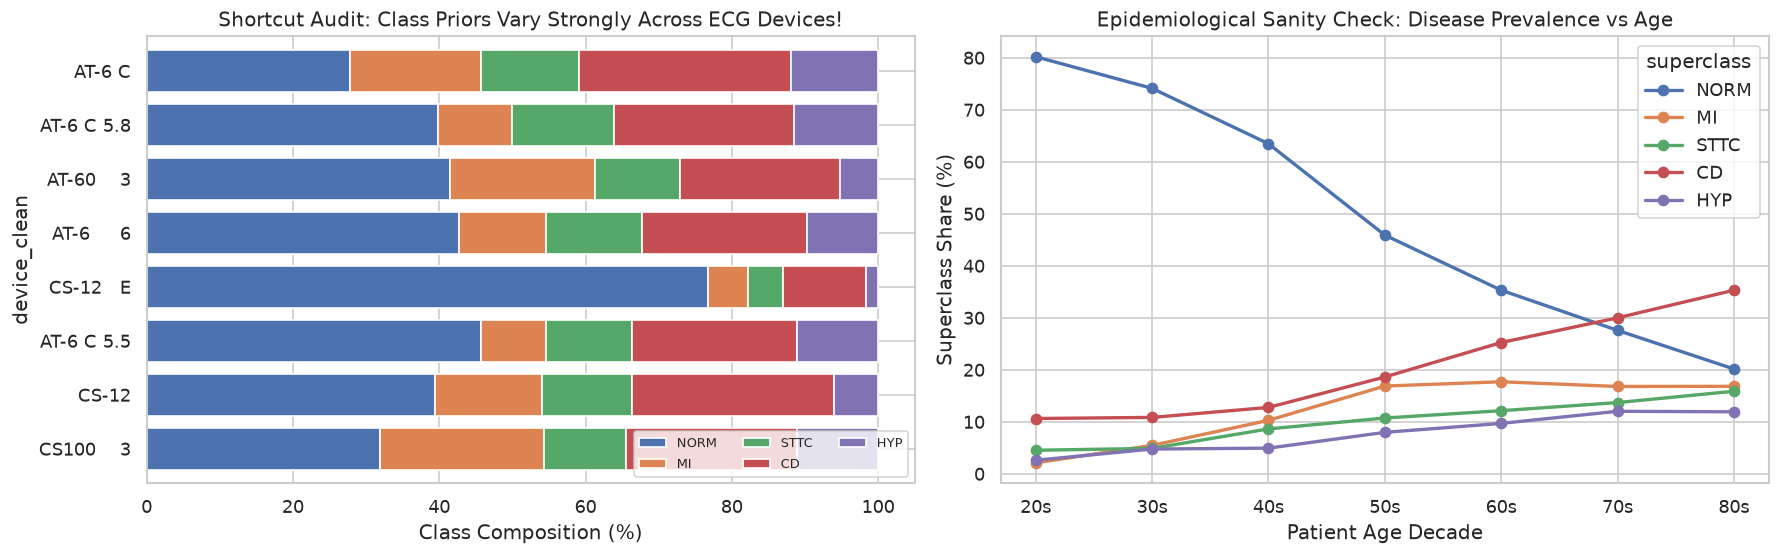

In [3]:
from scipy.stats import chi2_contingency

def cramers_v(x: pd.Series, y: pd.Series) -> float:
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    return float(np.sqrt(chi2 / (n * (min(r - 1, k - 1) + 1e-12))))

sub_valid_site = df.dropna(subset=["site"])
print(f"Cramér's V (device_clean × superclass) : {cramers_v(df['device_clean'], df['superclass']):.3f}")
print(f"Cramér's V (site         × superclass) : {cramers_v(sub_valid_site['site'], sub_valid_site['superclass']):.3f}")
print(f"Cramér's V (device_clean × strat_fold) : {cramers_v(df['device_clean'], df['strat_fold']):.3f}")

# Cross-check infarction_stadium1 vs MI presence in scp_codes
mi_codes = set(diag_scp.index[diag_scp["diagnostic_class"] == "MI"])
df["has_any_mi_code"] = df["scp_dict"].apply(lambda d: any(c in mi_codes for c in d))
inf_populated = df[df["infarction_stadium1"].notna()]
inf_without_mi = inf_populated[~inf_populated["has_any_mi_code"]]
print(f"\nRecords with infarction_stadium1 populated : {len(inf_populated):,}")
print(f"  ... of which LACK any MI code in scp_codes: {len(inf_without_mi):,} ({len(inf_without_mi)/len(inf_populated)*100:.2f}%)")
if len(inf_without_mi) > 0:
    display(inf_without_mi[["infarction_stadium1", "scp_codes", "report"]].head(6))

# Epidemiological sanity check + Device shortcut plot
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

top8_devs = df["device_clean"].value_counts().head(8).index
dev_ct = pd.crosstab(df.loc[df["device_clean"].isin(top8_devs), "device_clean"], df["superclass"], normalize="index") * 100
dev_ct.loc[top8_devs, ["NORM", "MI", "STTC", "CD", "HYP"]].plot(kind="barh", stacked=True, ax=axes[0], width=0.78)
axes[0].set_xlabel("Class Composition (%)")
axes[0].set_title("Shortcut Audit: Class Priors Vary Strongly Across ECG Devices!")
axes[0].legend(fontsize=8, ncol=3, loc="lower right")

valid_epi = df[df["age"].between(18, 90)].copy()
valid_epi["age_decade"] = pd.cut(valid_epi["age"], bins=[18, 30, 40, 50, 60, 70, 80, 90], labels=["20s", "30s", "40s", "50s", "60s", "70s", "80s"])
epi_curves = pd.crosstab(valid_epi["age_decade"], valid_epi["superclass"], normalize="index") * 100
epi_curves[["NORM", "MI", "STTC", "CD", "HYP"]].plot(marker="o", ax=axes[1], lw=2)
axes[1].set_ylabel("Superclass Share (%)")
axes[1].set_xlabel("Patient Age Decade")
axes[1].set_title("Epidemiological Sanity Check: Disease Prevalence vs Age")

plt.tight_layout()
plt.show()

## 5.3 Multivariate Waveform Feature Space: Hardware Batch Effects & Signal Outliers

Do different ECG recorder models (`device_clean`) leave a detectable signature in raw waveform statistics (DC offset, low-frequency drift power, high-frequency noise floor, amplitude scaling)?
We extract a 28-dimensional signal-quality & spectral vector on `2,000` stratified ECGs, apply `RobustScaler` + **PCA**, and run **IsolationForest** to flag multivariate waveform outliers.

IsolationForest flagged 40 / 2000 multivariate signal outliers (2% contamination)
Top multivariate outlier ECG IDs: [1426, 19528, 12532, 18714, 7105, 18599, 964, 4978, 8970, 11989]


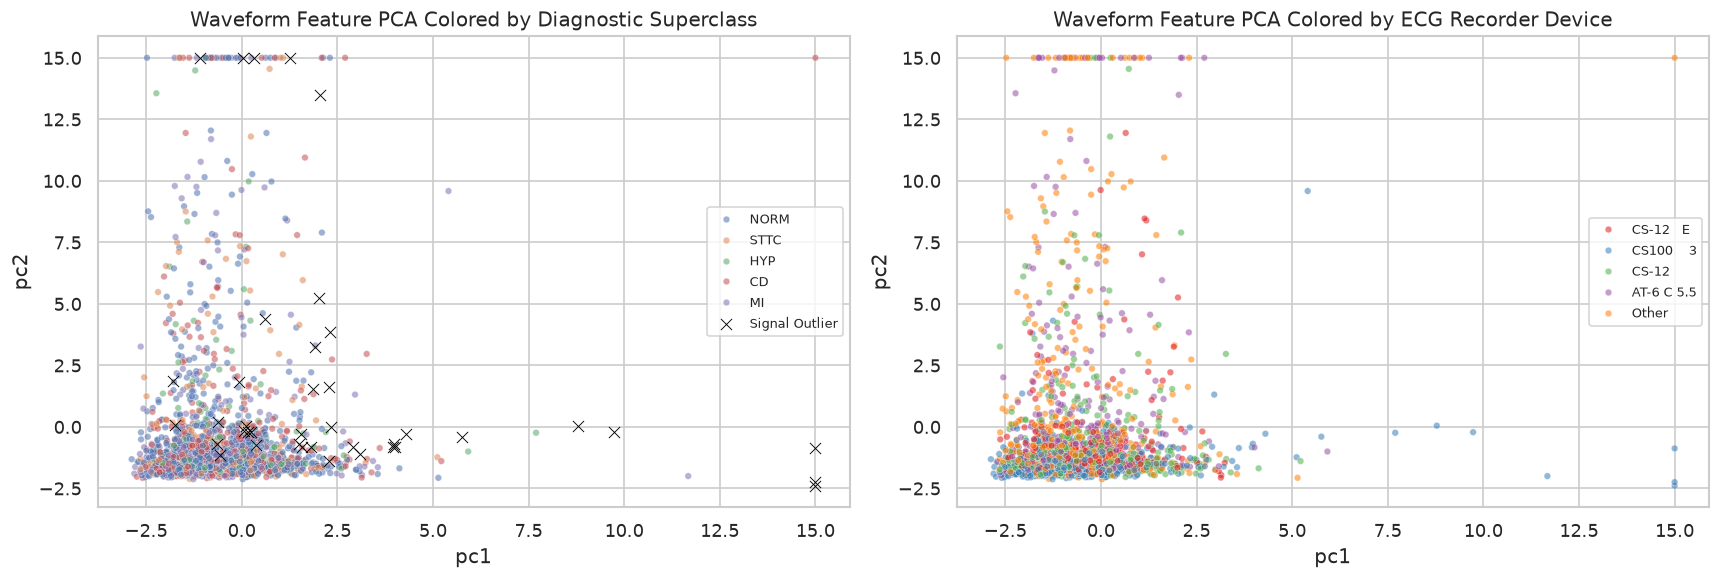

In [4]:
rng = np.random.default_rng(7)
feat_ids = rng.choice(df.index.values, size=2000, replace=False)

def extract_signal_features(eid: int) -> np.ndarray:
    sig, _ = wfdb.rdsamp(str(DATA_DIR / df.loc[eid, "filename_lr"]))
    if np.isnan(sig).any():
        sig = np.nan_to_num(sig)
    # 12 lead RMS + 12 lead abs DC offset + 4 spectral bandpowers on Lead II & V2
    rms = np.sqrt(np.mean(sig ** 2, axis=0))
    dc = np.abs(sig.mean(axis=0))
    f, p_ii = sp_signal.welch(sig[:, 1], fs=100.0, nperseg=256)
    _, p_v2 = sp_signal.welch(sig[:, 7], fs=100.0, nperseg=256)
    tot_ii = p_ii.sum() + 1e-12
    tot_v2 = p_v2.sum() + 1e-12
    bands = np.array([
        p_ii[f < 0.5].sum() / tot_ii,
        p_ii[(f >= 0.5) & (f < 15)].sum() / tot_ii,
        p_ii[f >= 15].sum() / tot_ii,
        p_v2[f < 0.5].sum() / tot_v2,
    ])
    return np.concatenate([rms, dc, bands])

with ThreadPoolExecutor(max_workers=16) as pool:
    X_raw = np.vstack(list(pool.map(extract_signal_features, feat_ids)))

X_scaled = RobustScaler().fit_transform(X_raw)
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
iso_pred = IsolationForest(contamination=0.02, random_state=42).fit_predict(X_scaled)

proj_df = pd.DataFrame({
    "ecg_id": feat_ids,
    "pc1": np.clip(X_pca[:, 0], -10, 15),
    "pc2": np.clip(X_pca[:, 1], -10, 15),
    "superclass": df.loc[feat_ids, "superclass"].values,
    "device": df.loc[feat_ids, "device_clean"].where(df.loc[feat_ids, "device_clean"].isin(df["device_clean"].value_counts().head(4).index), "Other").values,
    "is_outlier": iso_pred == -1,
})

print(f"IsolationForest flagged {proj_df['is_outlier'].sum()} / {len(proj_df)} multivariate signal outliers (2% contamination)")
print("Top multivariate outlier ECG IDs:", proj_df.loc[proj_df["is_outlier"], "ecg_id"].head(10).tolist())

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
sns.scatterplot(data=proj_df[~proj_df["is_outlier"]], x="pc1", y="pc2", hue="superclass", s=16, alpha=0.55, ax=axes[0])
sns.scatterplot(data=proj_df[proj_df["is_outlier"]], x="pc1", y="pc2", color="black", marker="x", s=45, label="Signal Outlier", ax=axes[0])
axes[0].set_title("Waveform Feature PCA Colored by Diagnostic Superclass")
axes[0].legend(fontsize=8)

sns.scatterplot(data=proj_df, x="pc1", y="pc2", hue="device", s=16, alpha=0.55, ax=axes[1], palette="Set1")
axes[1].set_title("Waveform Feature PCA Colored by ECG Recorder Device")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5.4 Consolidated Data-Cleaning Checklist for PTB-XL (`ptbxl/dataset.py`)

Across Notebooks `01–05`, our audit surfaced **8 concrete data-quality & cleaning findings**:

| # | Area | Finding | Recommended Cleaning / Pipeline Action |
|---|---|---|---|
| **1** | **Labels** | `411` records have **zero diagnostic SCP codes** (e.g. `AFIB`, `PACE`, `STACH` only) yet get mapped to `"NORM"` by fallback | Drop records with no diagnostic SCP code unless `'NORM' in scp_codes` |
| **2** | **Labels** | `_aggregate_class` sorts superclasses alphabetically (`CD < HYP < MI < NORM < STTC`), contradicting `_pick_subclass` on multi-label ECGs | Derive `diagnostic_class` directly from the chosen `diagnostic_subclass` (or train multi-label binary targets!) |
| **3** | **Labels** | Diagnostic statements include low likelihoods (`0.0`, `15.0`, `35.0`) | Add a `min_scp_likelihood: float = 50.0` (or `> 0.0`) threshold option |
| **4** | **Splits** | `min_class_fraction=0.0029` is computed independently per split, risking mismatched `class_names` between `train`, `val`, and `test` | Compute rare-class pruning on folds `1–8` (`train`) or full dataset so all splits share identical `class_names` |
| **5** | **Splits** | Folds `9–10` are `~98%+` human-validated while folds `1–8` contain `~32%` unvalidated machine labels | Add optional `only_human_validated: bool = False` flag (or lower loss weight on `validated_by_human == False`) |
| **6** | **Noise** | `train` & `val` set `filter_noise=True` (`0%` static/burst noise), while `test` sets `filter_noise=False` (`~20%` noisy), creating a sharp train/test shift | Either keep `static_noise` + bandpass filter (`0.5–40 Hz`), or evaluate `val` under the same noise regime as `test` |
| **7** | **Waveforms** | Unannotated flatlines (`>=0.5 s`), rail spikes (`>10 mV`), and `baseline_drift` (`7.3%`) remain after `filter_noise=True` | Apply zero-phase baseline removal (`0.5 Hz` high-pass) and drop/mask unannotated flatline or `>15 mV` clipped leads |
| **8** | **Metadata** | `age == 300` de-identification sentinel (`~293` elderly ECGs dropped by `age <= 100`), `device` padding whitespace, and `BMI` typos | Strip string columns; optionally clip `age > 89 -> 90` instead of dropping elderly pathology cases |